In [1]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset, load_windpower
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# file_name = "WindPowerQuantile_weighted_2026-03-16_12-38-33_nowcast_gen_ELSPOT_NO1"
# data_cfg = load_config(model_cfg.data.path)

model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_01_weighted.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_extended_2026-03-18_15-36-49_nowcast_ELSPOT_NO1"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3"  # "model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1"

In [3]:
data = load_dataset(data_cfg)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)


In [4]:
from data_processing.synthetic_data import synthetic_power_data

max_scaling = 1
data["Y_train_gen"], _ = synthetic_power_data(data, "X_train")
data["Y_test_gen"], _ = synthetic_power_data(data, "X_test")

0.0408 277.4044177913356
0.0408 162.85786893245583


In [5]:
# Baseline 1: Median of training set
def baseline_median(data, target):
    return np.full_like(target, np.percentile(data["Y_train_gen"], 50))

In [6]:
np.sqrt(
    np.mean((data["Y_train_gen"] - baseline_median(data, data["Y_train_gen"])) ** 2)
)

np.float64(14.214099310856884)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
MAE:  77.00714
ELSPOT NO2
Loading nowcast data for ELSPOT NO2...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2023-03-14 09:00:00
Maintenance hours in operational period: 217
Preprocessing done. X_train shape: (15599, 17, 10)
Preprocessing done. X_test shape: (2149, 17, 10)
MAE:  345.77286
ELSPOT NO3
Loading nowcast data for ELSPOT NO3...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-12 12:00:00
Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (19025, 24, 10)
Preprocessing done. X_test shape: (2160, 24, 10)
MAE:  432.0721
ELSPOT NO4
Loading nowcast data for ELSPOT NO4...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-11-29 15:00:00
Maintenance hours in operational period: 549
Preprocessing done. X_train shape: (17771, 13, 10)
Preprocessing done. X_test shape: (2160, 13, 10)
MAE:  195.01541


({'ELSPOT NO1': np.float64(119.54914309774134),
  'ELSPOT NO1_test': np.float64(166.74630968545648),
  'ELSPOT NO2': np.float64(534.115454617782),
  'ELSPOT NO2_test': np.float64(588.9921214168315),
  'ELSPOT NO3': np.float64(634.9614769872469),
  'ELSPOT NO3_test': np.float64(702.6642264175683),
  'ELSPOT NO4': np.float64(291.1482969635611),
  'ELSPOT NO4_test': np.float64(281.2876341637136)},
 {'ELSPOT NO1': np.float32(99.11118),
  'ELSPOT NO1_test': np.float32(144.55582),
  'ELSPOT NO2': np.float32(412.78616),
  'ELSPOT NO2_test': np.float32(394.92178),
  'ELSPOT NO3': np.float32(526.6279),
  'ELSPOT NO3_test': np.float32(561.7214),
  'ELSPOT NO4': np.float32(235.70184),
  'ELSPOT NO4_test': np.float32(249.95609)},
 {'ELSPOT NO1_median_bl': np.float32(77.00714),
  'ELSPOT NO1_shifted_bl': np.float64(91.2109541181635),
  'ELSPOT NO1_median_bl_test': np.float32(112.628876),
  'ELSPOT NO1_shifted_bl_test': np.float64(132.581356786695),
  'ELSPOT NO2_median_bl': np.float32(345.77286),
 

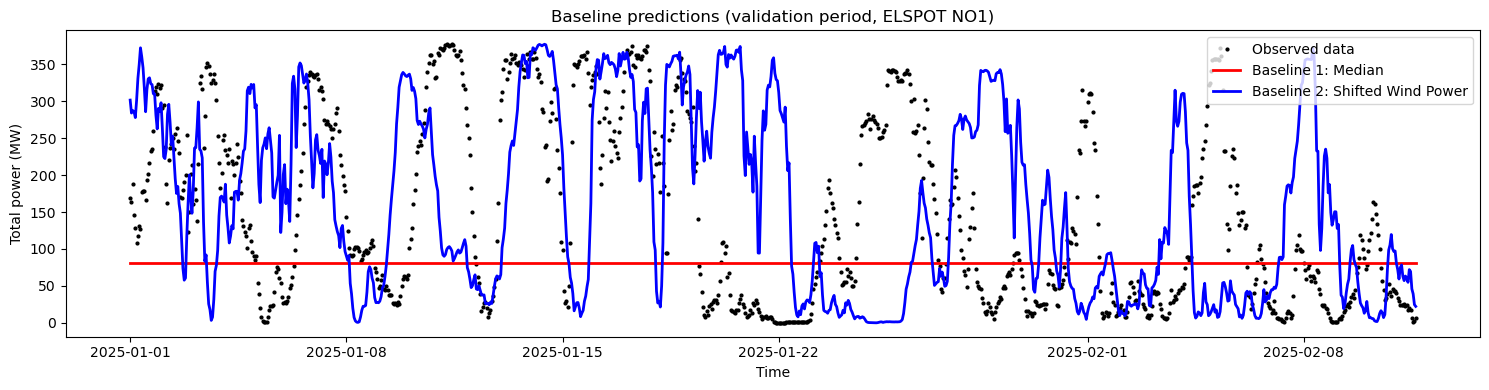

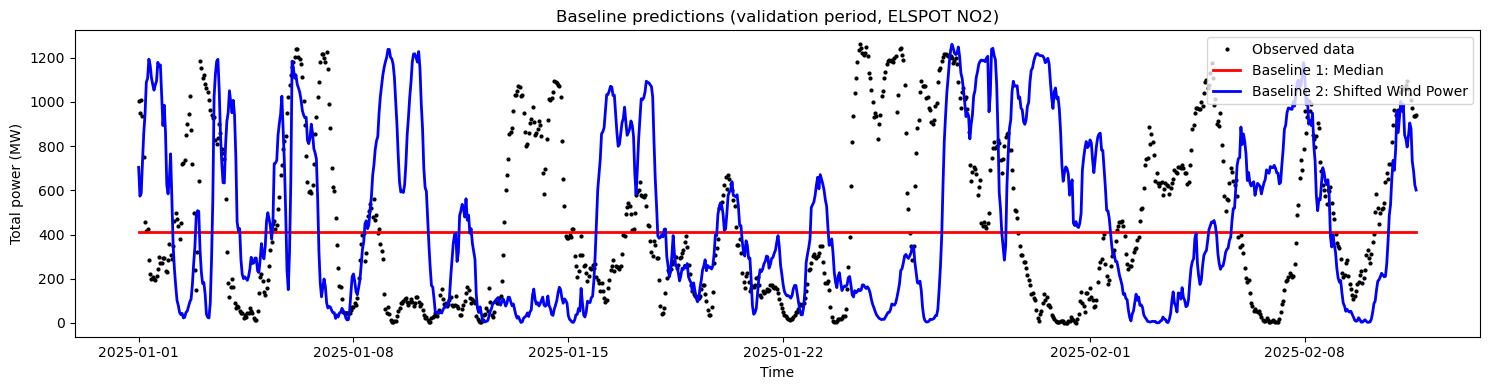

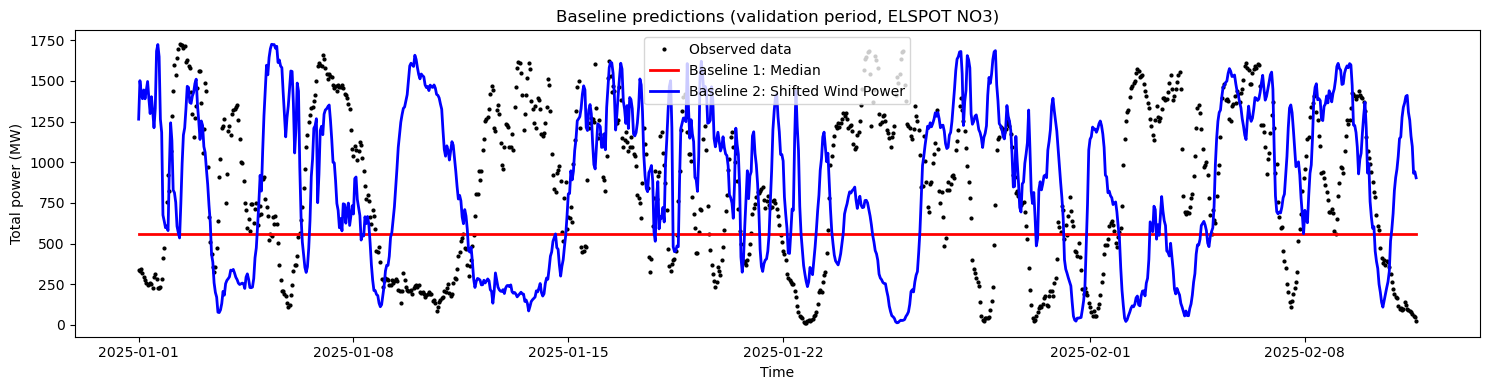

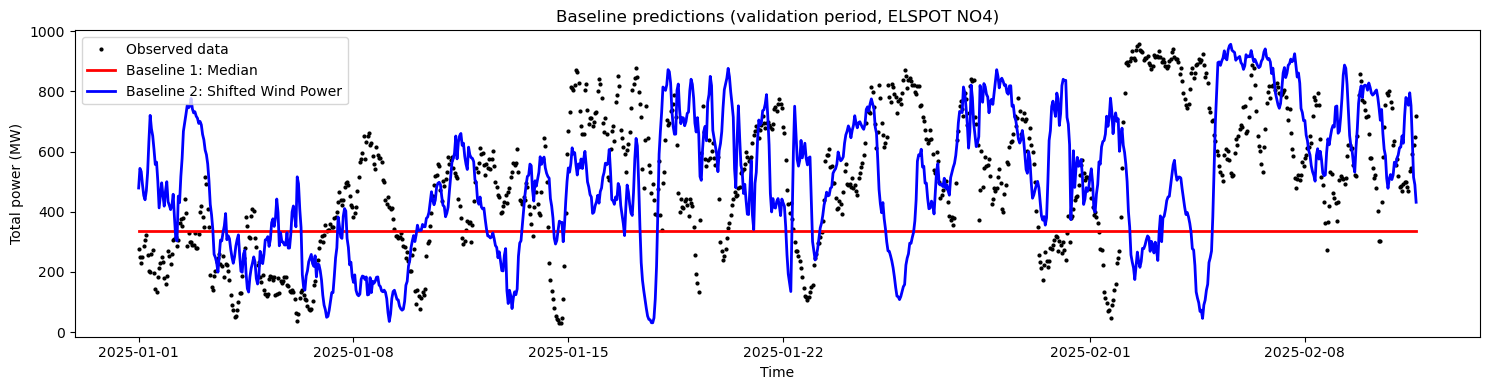

In [7]:
import properscoring as ps

rmses = {}
rmses_median_bl = {}
crps = {}
windpower = load_windpower("../data/wind_power_per_bidzone.parquet")
for i in range(1, 5):
    data = load_dataset(load_config(f"../configs/data/nowcast0{i}.yaml"))
    windpower_bz = pd.DataFrame(windpower[f"ELSPOT NO{i}"])
    s = windpower_bz.sort_index()
    s_hourly = s.asfreq("h")
    s["lag_3D"] = s_hourly.shift(72)
    s = s.dropna()

    s_filtered = s[s.index.isin(data["X_train_timestamps"])]
    rmse = np.sqrt(((s_filtered[f"ELSPOT NO{i}"] - s_filtered["lag_3D"]) ** 2).mean())
    rmses[f"ELSPOT NO{i}"] = rmse

    rmse_median_bl = np.sqrt(
        np.mean((data["Y_train_gen"] - baseline_median(data, data["Y_train_gen"])) ** 2)
    )
    rmses_median_bl[f"ELSPOT NO{i}"] = rmse_median_bl
    crps[f"ELSPOT NO{i}_median_bl"] = ps.crps_ensemble(
        data["Y_train_gen"], baseline_median(data, data["Y_train_gen"])
    ).mean()
    print(
        "MAE: ",
        np.mean(
            np.abs(data["Y_train_gen"] - baseline_median(data, data["Y_train_gen"]))
        ),
    )
    crps[f"ELSPOT NO{i}_shifted_bl"] = ps.crps_ensemble(
        s_filtered[f"ELSPOT NO{i}"], s_filtered["lag_3D"]
    ).mean()

    # -----eval------
    s_filtered = s[s.index.isin(data["X_test_timestamps"])]
    rmse = np.sqrt(((s_filtered[f"ELSPOT NO{i}"] - s_filtered["lag_3D"]) ** 2).mean())
    rmses[f"ELSPOT NO{i}_test"] = rmse

    rmse_median_bl = np.sqrt(
        np.mean((data["Y_test_gen"] - baseline_median(data, data["Y_test_gen"])) ** 2)
    )
    rmses_median_bl[f"ELSPOT NO{i}_test"] = rmse_median_bl

    crps[f"ELSPOT NO{i}_median_bl_test"] = ps.crps_ensemble(
        data["Y_test_gen"], baseline_median(data, data["Y_test_gen"]), axis=0
    ).mean()
    crps[f"ELSPOT NO{i}_shifted_bl_test"] = ps.crps_ensemble(
        s_filtered[f"ELSPOT NO{i}"], s_filtered["lag_3D"], axis=0
    ).mean()

    n_plot = 1000
    plt.figure(figsize=(15, 4))
    plt.plot(
        data["X_test_timestamps"][:n_plot],
        data["Y_test_gen"][:n_plot],
        ".",
        color="black",
        label="Observed data",
        markersize=4,
    )

    plt.plot(
        data["X_test_timestamps"][:n_plot],
        baseline_median(data, data["Y_test_gen"])[:n_plot],
        color="red",
        label="Baseline 1: Median",
        lw=2,
    )

    plt.plot(
        data["X_test_timestamps"][:n_plot],
        s_filtered["lag_3D"][:n_plot],
        color="blue",
        label="Baseline 2: Shifted Wind Power",
        lw=2,
    )
    plt.ylabel("Total power (MW)")
    plt.xlabel("Time")
    plt.legend()
    plt.title(f"Baseline predictions (validation period, ELSPOT NO{i})")
    plt.tight_layout()
    plt.savefig(f"../plots/baselines_ELSPOT_NO{i}.pdf")


rmses, rmses_median_bl, crps

In [8]:
data["Y_train_gen"]

array([389.97052, 358.13754, 351.07336, ..., 306.8174 , 320.14594,
       310.32816], shape=(17771,), dtype=float32)

In [9]:
np.concatenate([data["Y_train_gen"], data["Y_test_gen"]])

array([389.97052, 358.13754, 351.07336, ..., 473.33682, 525.5209 ,
       580.6206 ], shape=(19931,), dtype=float32)

ELSPOT NO1
Loading nowcast data for ELSPOT NO1...


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/load.py:743: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  weather_forecast["hour"] = weather_forecast.index.hour
/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


All parks operational from 2022-10-26 22:00:00
Maintenance hours in operational period: 8
Preprocessing done. X_train shape: (19122, 6, 10)
Preprocessing done. X_test shape: (2160, 6, 10)
0.0408 279.19079434616964
0.0408 156.77538035415193
                           ELSPOT NO1     lag_3D
2022-10-29 22:00:00+02:00    1.706421   2.083896
2022-10-29 23:00:00+02:00    0.586856   0.152336
2022-10-30 00:00:00+02:00    1.711352   2.146678
2022-10-30 01:00:00+02:00    2.233393   2.303276
2022-10-30 02:00:00+02:00    2.004236   3.589129
...                               ...        ...
2025-03-31 20:00:00+02:00    0.718897  15.244135
2025-03-31 21:00:00+02:00    1.328653  16.358755
2025-03-31 22:00:00+02:00    1.989333  19.088495
2025-03-31 23:00:00+02:00    0.489931  20.866534
2025-04-01 00:00:00+02:00    2.142749  20.184481

[21201 rows x 2 columns]
MAE:  4.982505911712165


({'ELSPOT NO1': np.float64(18.74877761919039),
  'ELSPOT NO1_test': np.float64(25.660491731880676)},
 {'ELSPOT NO1': np.float64(14.227941138024406),
  'ELSPOT NO1_test': np.float64(18.53114782602496)},
 {'ELSPOT NO1_median_bl': np.float64(4.982505911712165),
  'ELSPOT NO1_shifted_bl': np.float64(8.097659140513931),
  'ELSPOT NO1_median_bl_test': np.float64(7.2012129241200284),
  'ELSPOT NO1_shifted_bl_test': np.float64(12.673760779539448)})

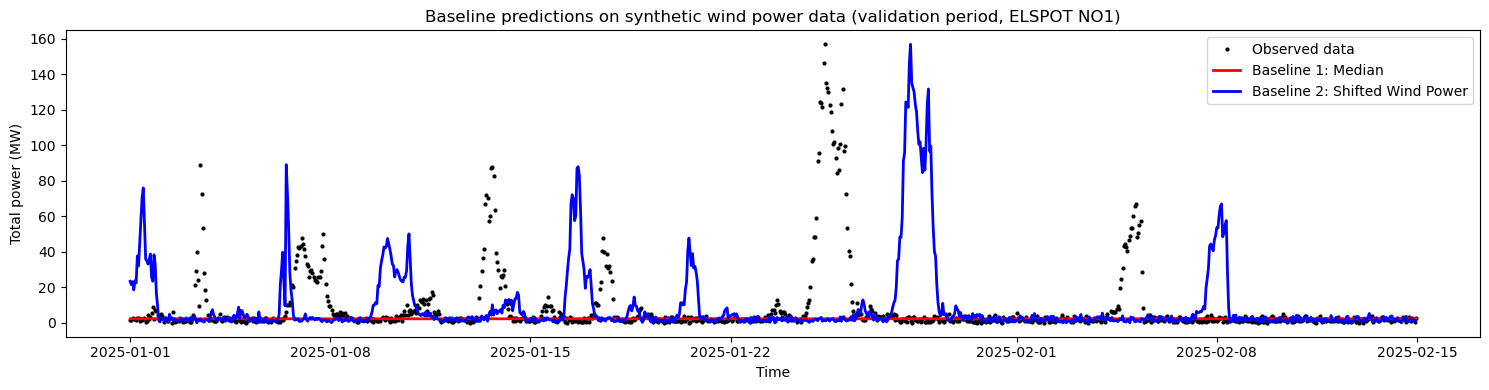

In [ ]:
import properscoring as ps

# synthetic target data
rmses = {}
rmses_median_bl = {}
crps = {}
mae = {}
windpower = load_windpower("../data/wind_power_per_bidzone.parquet")
for i in range(1, 2):
    data = load_dataset(load_config(f"../configs/data/nowcast0{i}.yaml"))
    data["Y_train_gen"], _ = synthetic_power_data(data, "X_train")
    data["Y_test_gen"], _ = synthetic_power_data(data, "X_test")
    windpower_bz = pd.DataFrame(
        np.concatenate([data["Y_train_gen"], data["Y_test_gen"]]),
        index=np.concatenate([data["X_train_timestamps"], data["X_test_timestamps"]]),
        columns=["ELSPOT NO1"],
    )
    s = windpower_bz.sort_index()
    s_hourly = s.asfreq("h")
    s["lag_3D"] = s_hourly.shift(72)
    s = s.dropna()
    print(s)

    s_filtered = s[s.index.isin(data["X_train_timestamps"])]
    rmse = np.sqrt(((s_filtered[f"ELSPOT NO{i}"] - s_filtered["lag_3D"]) ** 2).mean())
    rmses[f"ELSPOT NO{i}"] = rmse

    rmse_median_bl = np.sqrt(
        np.mean((data["Y_train_gen"] - baseline_median(data, data["Y_train_gen"])) ** 2)
    )
    rmses_median_bl[f"ELSPOT NO{i}"] = rmse_median_bl
    crps[f"ELSPOT NO{i}_median_bl"] = ps.crps_ensemble(
        data["Y_train_gen"], baseline_median(data, data["Y_train_gen"])
    ).mean()
    print(
        "MAE: ",
        np.mean(
            np.abs(data["Y_train_gen"] - baseline_median(data, data["Y_train_gen"]))
        ),
    )
    crps[f"ELSPOT NO{i}_shifted_bl"] = ps.crps_ensemble(
        s_filtered[f"ELSPOT NO{i}"], s_filtered["lag_3D"]
    ).mean()

    # -----eval------
    s_filtered = s[s.index.isin(data["X_test_timestamps"])]
    rmse = np.sqrt(((s_filtered[f"ELSPOT NO{i}"] - s_filtered["lag_3D"]) ** 2).mean())
    rmses[f"ELSPOT NO{i}_test"] = rmse

    rmse_median_bl = np.sqrt(
        np.mean((data["Y_test_gen"] - baseline_median(data, data["Y_test_gen"])) ** 2)
    )
    rmses_median_bl[f"ELSPOT NO{i}_test"] = rmse_median_bl

    crps[f"ELSPOT NO{i}_median_bl_test"] = ps.crps_ensemble(
        data["Y_test_gen"], baseline_median(data, data["Y_test_gen"]), axis=0
    ).mean()
    crps[f"ELSPOT NO{i}_shifted_bl_test"] = ps.crps_ensemble(
        s_filtered[f"ELSPOT NO{i}"], s_filtered["lag_3D"], axis=0
    ).mean()

    n_plot = 1080
    plt.figure(figsize=(15, 4))
    plt.plot(
        data["X_test_timestamps"][:n_plot],
        data["Y_test_gen"][:n_plot],
        ".",
        color="black",
        label="Observed data",
        markersize=4,
    )

    plt.plot(
        data["X_test_timestamps"][:n_plot],
        baseline_median(data, data["Y_test_gen"])[:n_plot],
        color="red",
        label="Baseline 1: Median",
        lw=2,
    )

    plt.plot(
        data["X_test_timestamps"][:n_plot],
        s_filtered["lag_3D"][:n_plot],
        color="blue",
        label="Baseline 2: Shifted Wind Power",
        lw=2,
    )
    plt.ylabel("Total power (MW)")
    plt.xlabel("Time")
    plt.legend()
    plt.title(
        f"Baseline predictions on synthetic wind power data (validation period, ELSPOT NO{i})"
    )
    plt.tight_layout()
    plt.savefig(f"../plots/baselines_synthetic_ELSPOT_NO{i}.pdf")


rmses, rmses_median_bl, crps